<a href="https://colab.research.google.com/github/Soju-004/Thyroid-Disease_Team-Data-Prerprocessing-Project/blob/Missingvalue_handling_Rayif/Missing_value_Handling_Rayif.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from imblearn.over_sampling import SMOTE

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = "/content/thyroidDF.csv"
df = pd.read_csv(file_path)

#EDA and Visualization


In [ ]:
df.head()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
0,29,F,f,f,f,f,f,f,f,t,...,NaN,f,NaN,f,NaN,f,NaN,other,-,840801013
1,29,F,f,f,f,f,f,f,f,f,...,128.0,f,NaN,f,NaN,f,NaN,other,-,840801014
2,41,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,11.0,other,-,840801042
3,36,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,26.0,other,-,840803046
4,32,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,36.0,other,S,840803047


In [ ]:
pd.set_option("display.max_columns",None)

In [ ]:
df.tail()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH_measured,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
9167,56,M,f,f,f,f,f,f,f,f,t,f,f,f,f,f,f,NaN,f,NaN,t,64.0,t,0.83,t,77.0,f,NaN,SVI,-,870119022
9168,22,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,t,91.0,t,0.92,t,99.0,f,NaN,SVI,-,870119023
9169,69,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,t,113.0,t,1.27,t,89.0,f,NaN,SVI,I,870119025
9170,47,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,t,75.0,t,0.85,t,88.0,f,NaN,other,-,870119027
9171,31,M,f,f,f,f,f,f,f,t,f,f,f,f,f,f,f,NaN,f,NaN,t,66.0,t,1.02,t,65.0,f,NaN,other,-,870119035


In [ ]:
df.sample()

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH_measured,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
772,35,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.2,t,2.1,t,151.0,t,1.02,t,148.0,f,NaN,other,-,841015027


In [ ]:
df.describe()

,age,TSH,T3,TT4,T4U,FTI,TBG,patient_id
count,9172.000000,8330.000000,6568.000000,8730.000000,8363.000000,8370.000000,349.000000,9.172000e+03
mean,73.555822,5.218403,1.970629,108.700305,0.976056,113.640746,29.870057,8.529473e+08
std,1183.976718,24.184006,0.887579,37.522670,0.200360,41.551650,21.080504,7.581969e+06
min,1.000000,0.005000,0.050000,2.000000,0.170000,1.400000,0.100000,8.408010e+08
25%,37.000000,0.460000,1.500000,87.000000,0.860000,93.000000,21.000000,8.504090e+08
50%,55.000000,1.400000,1.900000,104.000000,0.960000,109.000000,26.000000,8.510040e+08
75%,68.000000,2.700000,2.300000,126.000000,1.065000,128.000000,31.000000,8.607110e+08
max,65526.000000,530.000000,18.000000,600.000000,2.330000,881.000000,200.000000,8.701190e+08


In [ ]:
df.shape

(9172, 31)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9172 entries, 0 to 9171
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  9172 non-null   int64  
 1   sex                  8865 non-null   object 
 2   on_thyroxine         9172 non-null   object 
 3   query_on_thyroxine   9172 non-null   object 
 4   on_antithyroid_meds  9172 non-null   object 
 5   sick                 9172 non-null   object 
 6   pregnant             9172 non-null   object 
 7   thyroid_surgery      9172 non-null   object 
 8   I131_treatment       9172 non-null   object 
 9   query_hypothyroid    9172 non-null   object 
 10  query_hyperthyroid   9172 non-null   object 
 11  lithium              9172 non-null   object 
 12  goitre               9172 non-null   object 
 13  tumor                9172 non-null   object 
 14  hypopituitary        9172 non-null   object 
 15  psych                9172 non-null   o

In [ ]:
df.dtypes

,0
age,int64
sex,object
on_thyroxine,object
query_on_thyroxine,object
on_antithyroid_meds,object
sick,object
pregnant,object
thyroid_surgery,object
I131_treatment,object
query_hypothyroid,object


In [ ]:
df.columns

Index(['age', 'sex', 'on_thyroxine', 'query_on_thyroxine',
       'on_antithyroid_meds', 'sick', 'pregnant', 'thyroid_surgery',
       'I131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium',
       'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH_measured', 'TSH',
       'T3_measured', 'T3', 'TT4_measured', 'TT4', 'T4U_measured', 'T4U',
       'FTI_measured', 'FTI', 'TBG_measured', 'TBG', 'referral_source',
       'target', 'patient_id'],
      dtype='object')

In [ ]:
df['target'].value_counts()

,count
target,
-,6771
K,436
G,359
I,346
F,233
R,196
A,147
L,115
M,111


In [ ]:
df.isna().sum()

,0
age,0
sex,307
on_thyroxine,0
query_on_thyroxine,0
on_antithyroid_meds,0
sick,0
pregnant,0
thyroid_surgery,0
I131_treatment,0
query_hypothyroid,0


In [ ]:
(df.isna().sum() / len(df)) * 100

,0
age,0.000000
sex,3.347143
on_thyroxine,0.000000
query_on_thyroxine,0.000000
on_antithyroid_meds,0.000000
sick,0.000000
pregnant,0.000000
thyroid_surgery,0.000000
I131_treatment,0.000000
query_hypothyroid,0.000000


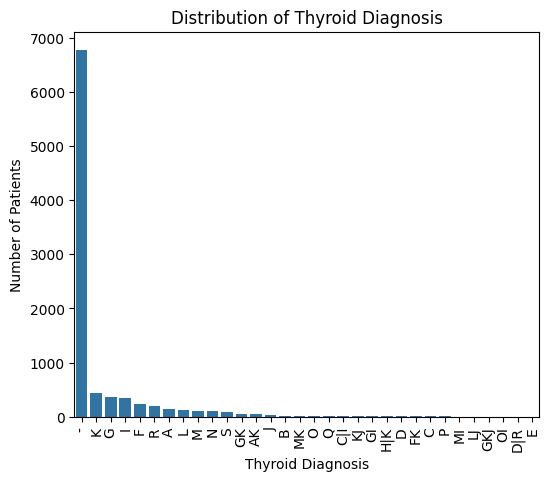

In [ ]:
# Before removing null values
plt.figure(figsize=(6, 5))

sns.countplot(
    data=df,
    x='target',
    order=df['target'].value_counts().index
)

plt.title('Distribution of Thyroid Diagnosis')
plt.xlabel('Thyroid Diagnosis')
plt.ylabel('Number of Patients')
plt.xticks(rotation=90)

plt.show()

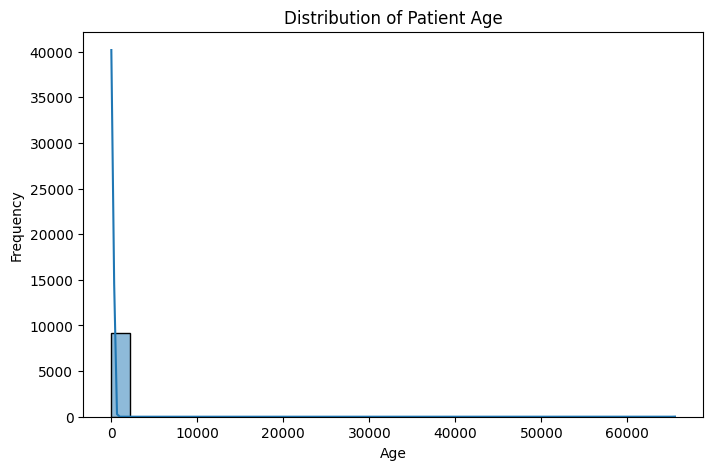

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Distribution of Patient Age')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

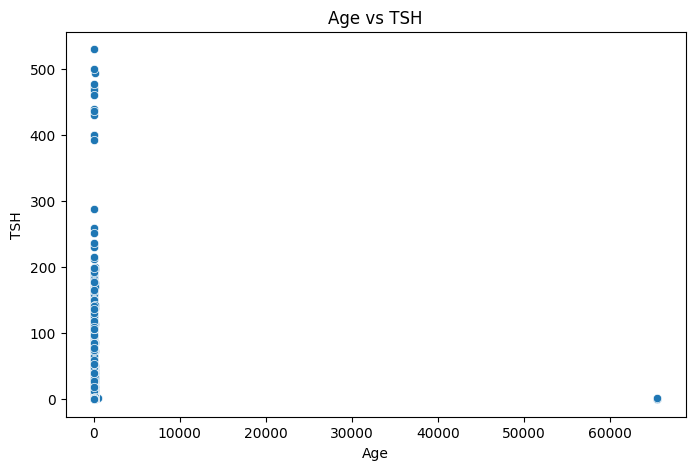

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='age', y='TSH')

plt.title('Age vs TSH')
plt.xlabel('Age')
plt.ylabel('TSH')

plt.show()

#Missing value Handling

**Before Data cleaning**

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['target'].value_counts()

,count
target,
-,6771
K,436
G,359
I,346
F,233
R,196
A,147
L,115
M,111


In [ ]:
df['referral_source'].value_counts()

,count
referral_source,
other,5493
SVI,2394
SVHC,956
STMW,255
SVHD,71
WEST,3


In [ ]:
df['sex'].value_counts()

,count
sex,
F,6073
M,2792


In [ ]:
df.isna().sum()

,0
age,0
sex,307
on_thyroxine,0
query_on_thyroxine,0
on_antithyroid_meds,0
sick,0
pregnant,0
thyroid_surgery,0
I131_treatment,0
query_hypothyroid,0


In [ ]:
df.isna().sum()/df.shape[0]*100

,0
age,0.000000
sex,3.347143
on_thyroxine,0.000000
query_on_thyroxine,0.000000
on_antithyroid_meds,0.000000
sick,0.000000
pregnant,0.000000
thyroid_surgery,0.000000
I131_treatment,0.000000
query_hypothyroid,0.000000


**Data cleaning**

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
class_counts = df["target"].value_counts()

valid_classes = class_counts[class_counts >= 2].index

df = df[df["target"].isin(valid_classes)]

In [ ]:
df["target"] = (
    df["target"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.$", "", regex=True)
)

In [ ]:
df["referral_source"] = df["referral_source"].str.strip()

In [ ]:
df["sex"] = df["sex"].str.strip()

In [ ]:
df = df.drop(columns=["TBG"])

In [ ]:
df.replace("?", np.nan, inplace=True)

**after Datacleaning**

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['target'].value_counts()

,count
target,
-,6771
K,436
G,359
I,346
F,233
R,196
A,147
L,115
M,111


In [ ]:
df['referral_source'].value_counts()

,count
referral_source,
other,5489
SVI,2393
SVHC,956
STMW,255
SVHD,71
WEST,3


In [ ]:
df['sex'].value_counts()

,count
sex,
F,6070
M,2790


In [ ]:
df.isna().sum()/df.shape[0]*100

,0
age,0.000000
sex,3.348969
on_thyroxine,0.000000
query_on_thyroxine,0.000000
on_antithyroid_meds,0.000000
sick,0.000000
pregnant,0.000000
thyroid_surgery,0.000000
I131_treatment,0.000000
query_hypothyroid,0.000000


###splitting

In [ ]:
X = df.drop("target", axis=1)
y = df["target"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (7333, 29)
Testing Data: (1834, 29)


In [ ]:
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

In [ ]:
num_cols

Index(['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'patient_id'], dtype='object')

In [ ]:
cat_cols

Index(['sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_meds',
       'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment',
       'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor',
       'hypopituitary', 'psych', 'TSH_measured', 'T3_measured', 'TT4_measured',
       'T4U_measured', 'FTI_measured', 'TBG_measured', 'referral_source'],
      dtype='object')

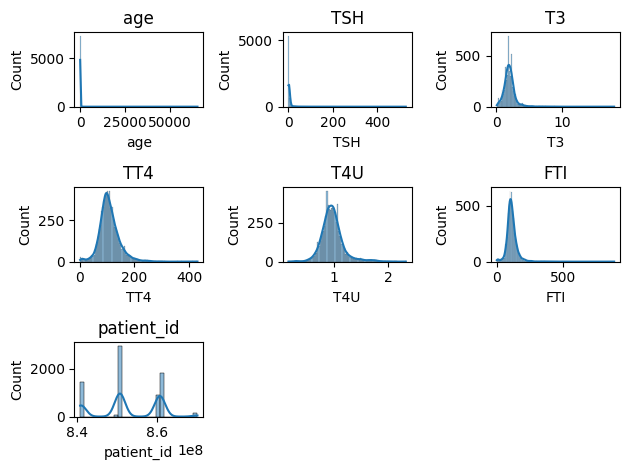

In [ ]:
for i,col in enumerate(num_cols,1):
  plt.subplot(3,3,i)
  sns.histplot(X_train[col],kde=True)
  plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
num_imputer=SimpleImputer(strategy='median')
X_train_num_imputer=num_imputer.set_output(transform='pandas').fit_transform(X_train[num_cols])
X_test_num_imputer=num_imputer.set_output(transform='pandas').transform(X_test[num_cols])

In [ ]:
X_train_num_imputer

,age,TSH,T3,TT4,T4U,FTI,patient_id
5734,47.0,3.000,1.9,123.0,1.02,120.0,860211005.0
1223,26.0,5.500,1.9,124.0,1.02,121.0,841115019.0
5318,62.0,0.760,1.9,105.0,0.85,124.0,851203017.0
5388,29.0,1.100,3.8,161.0,1.74,93.0,851209016.0
5650,76.0,4.100,1.9,56.0,0.76,73.0,860206023.0
...,...,...,...,...,...,...,...
5144,25.0,1.400,2.2,113.0,1.08,105.0,851120078.0
3066,29.0,1.400,1.9,104.0,0.96,109.0,850605087.0
5901,39.0,7.100,1.9,106.0,0.94,114.0,860221056.0
4492,58.0,0.600,2.0,151.0,1.05,144.0,850927004.0


In [ ]:
X_test_num_imputer

,age,TSH,T3,TT4,T4U,FTI,patient_id
5396,37.0,1.50,1.8,109.0,0.97,112.0,851209041.0
7778,87.0,3.30,1.1,64.0,0.55,116.0,860916063.0
5445,45.0,1.40,1.9,101.0,0.95,106.0,851211090.0
2075,38.0,0.20,2.0,78.0,0.85,92.0,850319004.0
7133,17.0,2.90,2.5,110.0,0.91,121.0,860731009.0
...,...,...,...,...,...,...,...
4442,14.0,3.60,1.2,103.0,0.88,118.0,850923029.0
2171,72.0,0.05,1.1,108.0,0.66,165.0,850327056.0
2373,24.0,0.15,2.7,116.0,0.82,143.0,850415027.0
8444,27.0,1.30,1.8,160.0,1.12,143.0,861111004.0
